# Part 5: The Digits Challenge

Run top to bottom. `FAST=0` runs at full scale (see README).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import mlcore as mc

FAST = mc.fast_mode()  # R2: FAST=0 for full scale
rng = np.random.default_rng(mc.SEED)  # R2 seed; experiments use mc.rng_for(tag)
print(f"FAST={FAST}")

FAST=True


## 5.0 Data

MNIST from `fetch_openml('mnist_784', version=1)`. The labels are strings. Pixels are divided by 255, the first 60 000 images are the training pool and the last 10 000 the test set.
- **Track A:** 1 ($y=+1$) vs 5 ($y=-1$). $N=500$ drawn from the pool (tag `5_A_draw`). Features are intensity and symmetry (`mc.intensity_symmetry`), scaled to $[-1,1]$ with training statistics, then mapped to tensor-product Legendre features of total degree $Q\in\{1,\dots,10\}$ (`mc.legendre_tensor_features`, DECISIONS row 7a).
- **Track B:** 4 ($y=+1$) vs 9 ($y=-1$). $N=1000$ drawn from the pool (tag `5_B_draw`). All 784 pixels in $[0,1]$ plus a bias, with no standardization (DECISIONS row 23).

The test sets are every 1/5 (or 4/9) image among the last 10 000. They are not touched until the single evaluation cell marked `# TEST`.

In [2]:
import time

from sklearn.datasets import fetch_openml   # data loading only (R1)

t0 = time.perf_counter()
X_mn, y_mn = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
X_mn = X_mn / 255.0
X_pool, y_pool, X_test, y_test = X_mn[:60_000], y_mn[:60_000], X_mn[60_000:], y_mn[60_000:]
print(f"loaded in {time.perf_counter() - t0:.1f} s; labels are {type(y_mn[0]).__name__}s, e.g. {y_mn[:5]}")

TRACKS = {"A": dict(pos="1", neg="5", N=500), "B": dict(pos="4", neg="9", N=1000)}
for name, tk in TRACKS.items():
    idx = np.flatnonzero(np.isin(y_pool, [tk["pos"], tk["neg"]]))
    sel = np.sort(mc.rng_for(f"5_{name}_draw").choice(idx, tk["N"], replace=False))
    te = np.flatnonzero(np.isin(y_test, [tk["pos"], tk["neg"]]))
    tk["img_tr"], tk["img_te"] = X_pool[sel], X_test[te]
    tk["y_tr"] = np.where(y_pool[sel] == tk["pos"], 1.0, -1.0)
    tk["y_te"] = np.where(y_test[te] == tk["pos"], 1.0, -1.0)
    tk["P_tr"] = mc.intensity_symmetry(tk["img_tr"]) if name == "A" else tk["img_tr"]   # raw inputs to each track
    tk["P_te"] = mc.intensity_symmetry(tk["img_te"]) if name == "A" else tk["img_te"]
    print(f"Track {name} ({tk['pos']} vs {tk['neg']}): train N = {tk['N']} ({np.sum(tk['y_tr'] == 1)} positives), "
          f"test {te.size} ({np.sum(tk['y_te'] == 1)} positives)")

loaded in 2.0 s; labels are strs, e.g. ['5' '0' '4' '1' '9']
Track A (1 vs 5): train N = 500 (278 positives), test 2027 (1135 positives)
Track B (4 vs 9): train N = 1000 (464 positives), test 1991 (982 positives)


## 5.1 Model selection by 10-fold CV on the training sample

Candidates for each track:

| Family | Unpenalized | L2 | L1 |
|---|---|---|---|
| Pocket ($T=1000$, $w_0=w_{lin}$) | yes | — (DECISIONS row 7b) | — |
| Linear regression for classification | `lstsq` (minimum norm) | $E_{in}+\frac{\lambda}{N}\lVert\tilde w\rVert^2$, `ridge_svd` | $E_{in}+\lambda\lVert\tilde w\rVert_1$, FISTA |
| Logistic regression | L-BFGS (cap 1000) | $E_{in}+\lambda\lVert\tilde w\rVert^2$, warm-started L-BFGS | $E_{in}+\lambda\lVert\tilde w\rVert_1$, FISTA |

The bias is never penalized. Each L1 grid runs from $\lambda_{max}$, the smallest $\lambda$ with all weights zero, computed once on the training sample, down three decades. The L1 paths use accelerated proximal gradient (`mc.prox_path(..., accel=True)`, tolerance $10^{-6}$): plain ISTA took about 7 times longer on Track B.
Track A crosses every candidate with $Q=1,\dots,10$ and refits the $[-1,1]$ scaling inside each fold. Track B has no data-dependent preprocessing.

The selection criterion is the 10-fold CV classification error (`mc.cv_curve`, loss `"01"`). Ties go to the simpler model: smaller $Q$, then the family order linear regression, logistic, Pocket, then stronger regularization (DECISIONS row 23).

In [3]:
LAM_RIDGE = np.logspace(4, -3, 15)        # 4.2 form, decreasing
LAM_LOG2 = np.logspace(0, -5, 11)         # 3.6 form, decreasing
L1_SPAN = np.logspace(0, -3, 13)          # fraction of lambda_max, decreasing


def design(name, P_tr, P_other, Q):
    # A: scale on P_tr, then Legendre; B: pixels + bias
    if name == "A":
        F_tr, prm = mc.minmax_scale(P_tr)
        return mc.legendre_tensor_features(F_tr, Q), mc.legendre_tensor_features(mc.apply_minmax(P_other, prm), Q)
    return mc.add_bias(P_tr), mc.add_bias(P_other)


def l1_grids(X, y):
    # lambda_max for squared and logistic loss
    lmax_lin = 2 * np.max(np.abs(X[:, 1:].T @ (y - y.mean()))) / y.size
    p = np.mean(y == 1)
    w_b = np.r_[np.log(p / (1 - p)), np.zeros(X.shape[1] - 1)]
    lmax_log = np.max(np.abs(mc.logistic_loss_grad(w_b, X, y)[1][1:]))
    return lmax_lin * L1_SPAN, lmax_log * L1_SPAN


def fit(family, penalty, lams, X, y, rng=None):
    # weights (P, m), one row per lambda
    m = X.shape[1]
    if family == "linreg":
        if penalty == "none":
            return mc.solve_lstsq(X, y)[None]
        if penalty == "L2":
            return mc.ridge_svd(X, y, lams)["W"]
        lg = lambda v: mc.linreg_loss_grad(v, X, y)  # noqa: E731
        return mc.prox_path(lg, m, 1 / mc.lipschitz_linreg(X), lams, 20_000, tol=1e-6, accel=True)[0]
    if family == "logreg":
        if penalty == "none":
            return mc.lbfgs(lambda v: mc.logistic_loss_grad(v, X, y), np.zeros(m), maxiter=1000)[0][None]
        if penalty == "L2":
            W, w = [], np.zeros(m)
            for lam in lams:
                w, _ = mc.lbfgs(lambda v: mc.logistic_loss_grad(v, X, y, lam), w)
                W.append(w)
            return np.array(W)
        lg = lambda v: mc.logistic_loss_grad(v, X, y)  # noqa: E731
        return mc.prox_path(lg, m, 1 / mc.lipschitz_logistic(X), lams, 20_000, tol=1e-6, accel=True)[0]
    return mc.pocket(X, y, rng, T=1000, w0=mc.solve_lstsq(X, y))[0][None]


def candidates(name, Q):
    X_full, _ = design(name, TRACKS[name]["P_tr"], TRACKS[name]["P_tr"][:1], Q)
    lin1, log1 = l1_grids(X_full, TRACKS[name]["y_tr"])
    return [("linreg", "L2", LAM_RIDGE), ("linreg", "L1", lin1), ("linreg", "none", [0.0]),
            ("logreg", "L2", LAM_LOG2), ("logreg", "L1", log1), ("logreg", "none", [0.0]),
            ("pocket", "none", [0.0])]


FAMILY_ORDER = {"linreg": 0, "logreg": 1, "pocket": 2}
cv_rows = {}
for name, tk in TRACKS.items():
    t0 = time.perf_counter()
    folds = mc.kfold_indices(tk["N"], 10, mc.rng_for(f"5_{name}_cv"))
    rng_pocket = mc.rng_for(f"5_{name}_pocket")
    rows = []
    for Q in (range(1, 11) if name == "A" else [None]):
        for family, penalty, lams in candidates(name, Q):
            def fp(P_tr, y_tr, P_val, family=family, penalty=penalty, lams=lams, Q=Q):
                Xtr, Xval = design(name, P_tr, P_val, Q)
                return fit(family, penalty, lams, Xtr, y_tr, rng_pocket) @ Xval.T
            mean_err, fold_err = mc.cv_curve(fp, tk["P_tr"], tk["y_tr"], folds, loss="01")
            for k, lam in enumerate(lams):
                rows.append(dict(Q=Q, family=family, penalty=penalty, lam=lam, k=k, lams=lams,
                                 cv=mean_err[k], se=mc.mean_se(fold_err[:, k])[1]))
    # simplest first, so ties go to the simpler model
    rows.sort(key=lambda r: ((r["Q"] or 0), FAMILY_ORDER[r["family"]], {"L2": 0, "L1": 1, "none": 2}[r["penalty"]], r["k"]))
    best = int(np.argmin([r["cv"] for r in rows]))
    cv_rows[name] = dict(rows=rows, best=rows[best])
    print(f"\nTrack {name}: {len(rows)} candidates, 10-fold CV in {time.perf_counter() - t0:.0f} s")
    print(f"  {'family':<8}{'penalty':<8}{'best CV error':>20}{'at':>26}")
    for family in ("linreg", "logreg", "pocket"):
        for penalty in ("none", "L2", "L1"):
            sub = [r for r in rows if r["family"] == family and r["penalty"] == penalty]
            if not sub:
                continue
            b = sub[int(np.argmin([r["cv"] for r in sub]))]
            where = (f"Q = {b['Q']}, " if b["Q"] else "") + (f"lambda = {b['lam']:.3g}" if penalty != "none" else "")
            print(f"  {family:<8}{penalty:<8}{b['cv']:>12.4f} ± {b['se']:.4f}{where:>26}")
    b = cv_rows[name]["best"]
    print(f"  SELECTED: {b['family']} {b['penalty']}" + (f", Q = {b['Q']}" if b["Q"] else "")
          + (f", lambda = {b['lam']:.3g}" if b["penalty"] != "none" else "") + f"  (CV error {b['cv']:.4f} ± {b['se']:.4f})")


Track A: 550 candidates, 10-fold CV in 30 s
  family  penalty        best CV error                        at
  linreg  none          0.1240 ± 0.0122                   Q = 9, 
  linreg  L2            0.1260 ± 0.0119   Q = 4, lambda = 0.00316
  linreg  L1            0.1300 ± 0.0113  Q = 6, lambda = 0.000471
  logreg  none          0.1240 ± 0.0126                   Q = 7, 
  logreg  L2            0.1260 ± 0.0103     Q = 5, lambda = 1e-05
  logreg  L1            0.1240 ± 0.0111  Q = 5, lambda = 0.000118
  pocket  none          0.1180 ± 0.0144                   Q = 4, 
  SELECTED: pocket none, Q = 4  (CV error 0.1180 ± 0.0144)



Track B: 55 candidates, 10-fold CV in 124 s
  family  penalty        best CV error                        at
  linreg  none          0.1210 ± 0.0091                          
  linreg  L2            0.0450 ± 0.0078               lambda = 10
  linreg  L1            0.0530 ± 0.0082          lambda = 0.00118
  logreg  none          0.0560 ± 0.0076                          
  logreg  L2            0.0440 ± 0.0088            lambda = 0.001
  logreg  L1            0.0580 ± 0.0117          lambda = 0.00093
  pocket  none          0.0620 ± 0.0126                          
  SELECTED: logreg L2, lambda = 0.001  (CV error 0.0440 ± 0.0088)


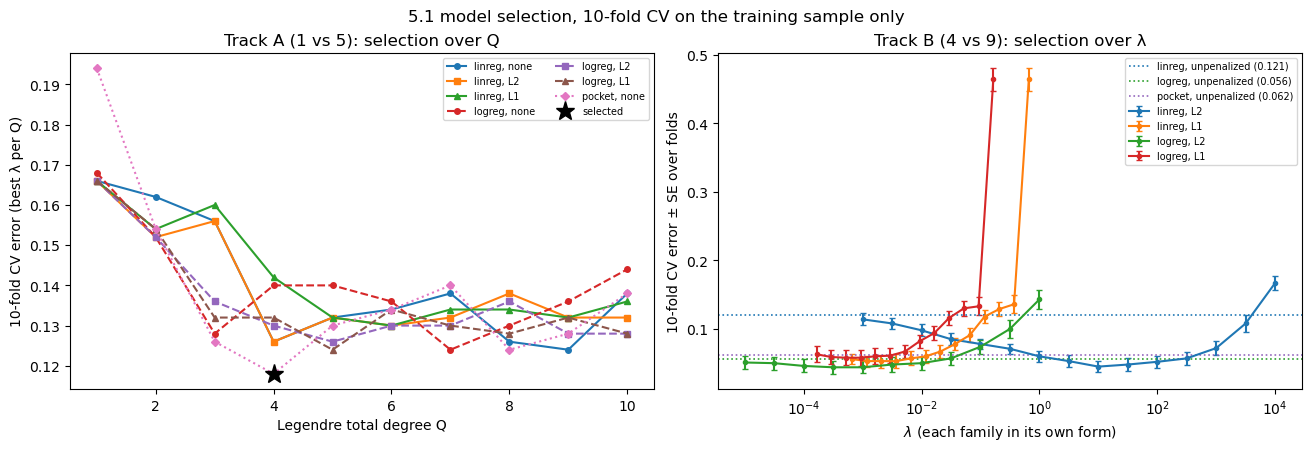

In [4]:
# CV error per Q (A) and per lambda (B)
rowsA = cv_rows["A"]["rows"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True)
ax = axes[0]
for (family, penalty), mk in zip([(f, p) for f in ("linreg", "logreg") for p in ("none", "L2", "L1")] + [("pocket", "none")],
                                 ("o", "s", "^", "o", "s", "^", "D")):
    ls = "-" if family == "linreg" else (":" if family == "pocket" else "--")
    best_q = [min(r["cv"] for r in rowsA if r["family"] == family and r["penalty"] == penalty and r["Q"] == Q) for Q in range(1, 11)]
    ax.plot(range(1, 11), best_q, ls=ls, marker=mk, ms=4, label=f"{family}, {penalty}")
bA = cv_rows["A"]["best"]
ax.plot(bA["Q"], bA["cv"], "k*", ms=14, label="selected")
ax.set(xlabel="Legendre total degree Q", ylabel="10-fold CV error (best λ per Q)", title="Track A (1 vs 5): selection over Q")
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
rowsB = cv_rows["B"]["rows"]
for (family, penalty), c in zip([("linreg", "L2"), ("linreg", "L1"), ("logreg", "L2"), ("logreg", "L1")], ("C0", "C1", "C2", "C3")):
    sub = [r for r in rowsB if r["family"] == family and r["penalty"] == penalty]
    lam = np.array([r["lam"] for r in sub])
    ax.errorbar(lam, [r["cv"] for r in sub], yerr=[r["se"] for r in sub], color=c, marker="o", ms=3, capsize=2, label=f"{family}, {penalty}")
for (family, penalty), c in zip([("linreg", "none"), ("logreg", "none"), ("pocket", "none")], ("C0", "C2", "C4")):
    r = [r for r in rowsB if r["family"] == family and r["penalty"] == penalty][0]
    ax.axhline(r["cv"], color=c, ls=":", lw=1.2, label=f"{family}, unpenalized ({r['cv']:.3f})")
ax.set(xscale="log", xlabel=r"$\lambda$ (each family in its own form)", ylabel="10-fold CV error ± SE over folds", title="Track B (4 vs 9): selection over λ")
ax.legend(fontsize=7)
fig.suptitle("5.1 model selection, 10-fold CV on the training sample only")
mc.savefig(fig, "5_1_selection")
plt.show()

**Interpretation.** In Track A, Pocket with $Q=4$ wins (CV $0.118\pm0.014$), but every model is within half a fold-SE of it (0.124 to 0.130) and the penalty changes nothing; only $Q$ matters. In Track B, L2 logistic regression with $\lambda=10^{-3}$ wins ($0.044\pm0.009$), tied with ridge (0.045). The unpenalized models are clearly worse (linear regression 0.121, logistic 0.056, Pocket 0.062), and L1 is worse than L2.

## 5.2(a) The selected model on the test set, once

Each track's selected model is refitted on the whole training sample and evaluated on the test set exactly once. The 95% Hoeffding bound uses $M=1$: the test set played no part in choosing the hypothesis.

In [5]:
final = {}
for name, tk in TRACKS.items():
    b = cv_rows[name]["best"]
    X_tr, X_te = design(name, tk["P_tr"], tk["P_te"], b["Q"])
    w = fit(b["family"], b["penalty"], b["lams"], X_tr, tk["y_tr"], mc.rng_for(f"5_{name}_final"))[b["k"]]
    final[name] = dict(w=w, X_tr=X_tr, X_te=X_te, best=b)

# TEST: evaluated once
for name, tk in TRACKS.items():
    f = final[name]
    s_te = f["X_te"] @ f["w"]
    f["s_te"] = s_te
    e_tr, e_te = mc.ein_01(f["w"], f["X_tr"], tk["y_tr"]), mc.ein_01(f["w"], f["X_te"], tk["y_te"])
    eps = mc.hoeffding_eps(tk["y_te"].size, 0.05, M=1)
    f.update(e_te=e_te, eps=eps)
    b = f["best"]
    print(f"Track {name}: {b['family']} {b['penalty']}" + (f", Q = {b['Q']}" if b["Q"] else "") + (f", lambda = {b['lam']:.3g}" if b["penalty"] != "none" else "")
          + f" | Ein {e_tr:.4f} | CV {b['cv']:.4f} | Etest {e_te:.4f} on {tk['y_te'].size} images | "
          f"95% Hoeffding: Eout <= {e_te + eps:.4f} (eps = {eps:.4f}) | weights with |w| > 1e-8: {np.sum(np.abs(f['w'][1:]) > 1e-8)} of {f['w'].size - 1}")

Track A: pocket none, Q = 4 | Ein 0.1220 | CV 0.1180 | Etest 0.1411 on 2027 images | 95% Hoeffding: Eout <= 0.1713 (eps = 0.0302) | weights with |w| > 1e-8: 14 of 14
Track B: logreg L2, lambda = 0.001 | Ein 0.0110 | CV 0.0440 | Etest 0.0412 on 1991 images | 95% Hoeffding: Eout <= 0.0716 (eps = 0.0304) | weights with |w| > 1e-8: 548 of 784


**Interpretation.** Track A has $E_{test}=0.141$ on 2027 images, so $E_{out}\le0.171$ with 95% confidence; Track B has $E_{test}=0.041$ on 1991 images, so $E_{out}\le0.072$ ($\epsilon=0.030$, $M=1$). The bound holds only because the test set played no part in choosing the model. Had it picked among the 550 or 55 candidates, the reported hypothesis would depend on the test data, and the union bound would need $M$ equal to the number of candidates examined. Track A's test error exceeds its CV estimate because the winner is the best of 550 noisy CV estimates (as in 4.5).

## 5.2(b) What the models learned

Track A: the selected decision boundary in the scaled (intensity, symmetry) plane, with the training points.
Track B: the weights of the L1 and L2 models, each at its own CV-selected $\lambda$ and refitted on all 1000 training images, shown as 28×28 images. Red pixels push towards 4 ($w_j>0$), blue towards 9. These extra fits use the training sample only.

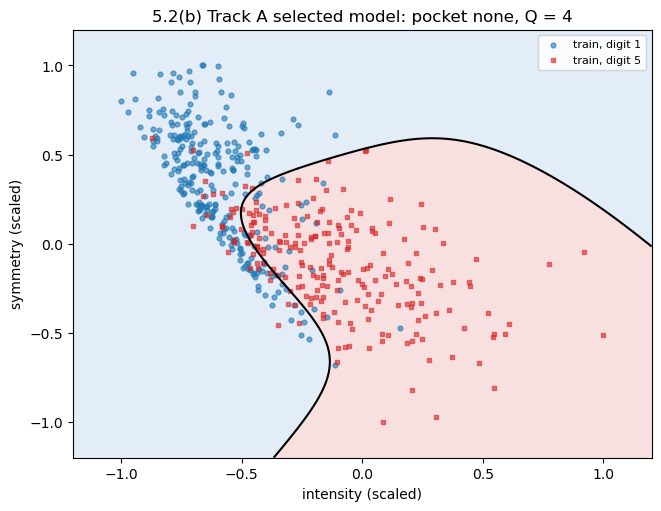

In [6]:
tA = TRACKS["A"]
F_trA, prmA = mc.minmax_scale(tA["P_tr"])
QA = final["A"]["best"]["Q"]
g1, g2 = np.meshgrid(np.linspace(-1.2, 1.2, 400), np.linspace(-1.2, 1.2, 400))
sA = (mc.legendre_tensor_features(np.column_stack([g1.ravel(), g2.ravel()]), QA) @ final["A"]["w"]).reshape(g1.shape)
fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)
ax.contourf(g1, g2, sA > 0, levels=[-0.5, 0.5, 1.5], colors=["#f4cccc", "#cfe2f3"], alpha=0.6)
ax.contour(g1, g2, sA, levels=[0], colors="k", linewidths=1.5)
for lab, mk, c, dg in ((1, "o", "C0", "1"), (-1, "s", "C3", "5")):
    ax.scatter(*F_trA[tA["y_tr"] == lab].T, marker=mk, s=12, c=c, alpha=0.6, label=f"train, digit {dg}")
bA = final["A"]["best"]
ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), xlabel="intensity (scaled)", ylabel="symmetry (scaled)",
       title=f"5.2(b) Track A selected model: {bA['family']} {bA['penalty']}, Q = {QA}" + (f", λ = {bA['lam']:.3g}" if bA["penalty"] != "none" else ""))
ax.legend(fontsize=8)
mc.savefig(fig, "5_2b_track_a_boundary")
plt.show()

236 of 784 pixels are 0 in every training image (weight stays 0)


logistic L2: lambda = 0.001, CV error 0.0440, 548 non-zero pixel weights


logistic L1: lambda = 0.00093, CV error 0.0580, 88 non-zero pixel weights


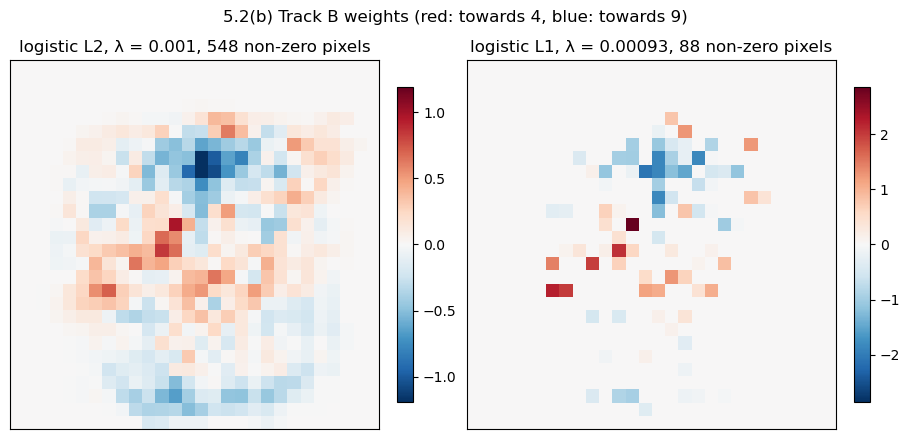

In [7]:
tB = TRACKS["B"]
XB = mc.add_bias(tB["P_tr"])
rowsB = cv_rows["B"]["rows"]
print(f"{np.all(tB['P_tr'] == 0, axis=0).sum()} of 784 pixels are 0 in every training image (weight stays 0)")
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), constrained_layout=True)
for ax, penalty in zip(axes, ("L2", "L1")):
    sub = [r for r in rowsB if r["family"] == "logreg" and r["penalty"] == penalty]
    b = sub[int(np.argmin([r["cv"] for r in sub]))]
    w = fit("logreg", penalty, b["lams"], XB, tB["y_tr"])[b["k"]]
    nz = np.sum(np.abs(w[1:]) > 1e-8)
    print(f"logistic {penalty}: lambda = {b['lam']:.3g}, CV error {b['cv']:.4f}, {nz} non-zero pixel weights")
    v = np.max(np.abs(w[1:]))
    im = ax.imshow(w[1:].reshape(28, 28), cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set(xticks=[], yticks=[], title=f"logistic {penalty}, λ = {b['lam']:.3g}, {nz} non-zero pixels")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("5.2(b) Track B weights (red: towards 4, blue: towards 9)")
mc.savefig(fig, "5_2b_track_b_weights")
plt.show()

**Interpretation.** In Track A the two features overlap; the degree-4 boundary bends around the 5s but cannot separate the overlap, so the error stays near 12%. In Track B, 236 pixels are blank in every training image and keep zero weight. L2 spreads weight smoothly over the other 548 pixels, while L1 keeps 88 scattered ones and is worse (CV 0.058 against 0.044), because the evidence for a stroke is spread over correlated neighbouring pixels.

## 5.2(c) Misclassified test images

Track B: the 6 most confident mistakes of each kind. The selected model is logistic, so it gives $P(y=4\mid x)$ directly.

82 misclassified test images (47 true 4, 35 true 9)


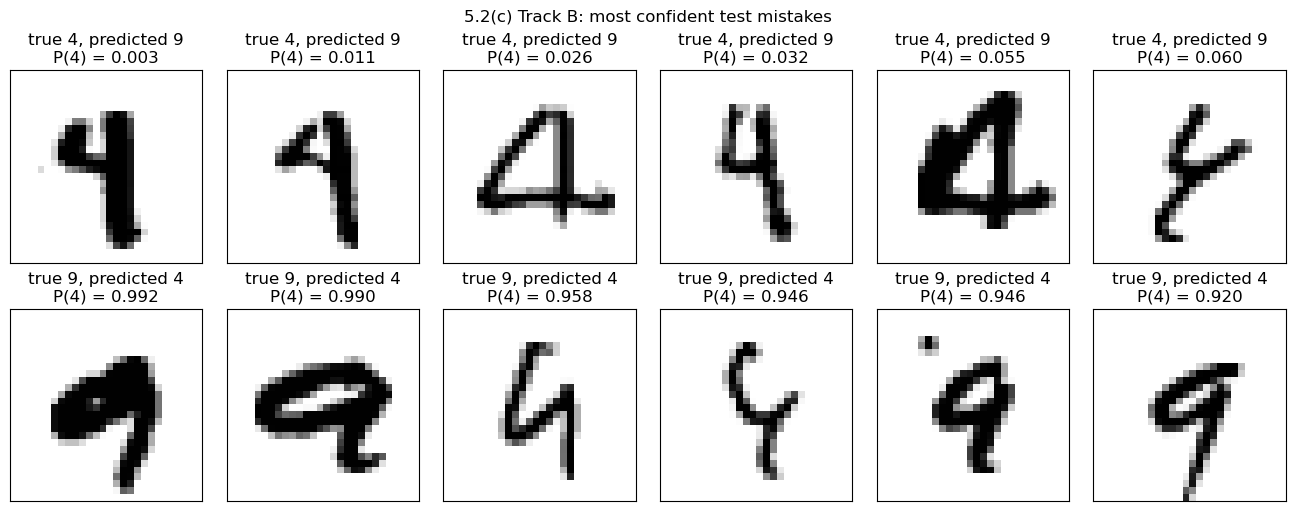

In [8]:
tk, f = TRACKS["B"], final["B"]
assert f["best"]["family"] == "logreg"
prob = mc.logistic_proba(f["w"], f["X_te"])
wrong = np.flatnonzero(np.where(f["s_te"] > 0, 1, -1) != tk["y_te"])
margin = -tk["y_te"][wrong] * f["s_te"][wrong]  # larger = more confidently wrong
picks = []
for lab in (1, -1):
    m = tk["y_te"][wrong] == lab
    picks += list(wrong[m][np.argsort(-margin[m])][:6])
print(f"{wrong.size} misclassified test images ({np.sum(tk['y_te'][wrong] == 1)} true 4, {np.sum(tk['y_te'][wrong] == -1)} true 9)")
fig, axes = plt.subplots(2, 6, figsize=(13, 5), constrained_layout=True)
for ax, i in zip(axes.ravel(), picks):
    ax.imshow(tk["img_te"][i].reshape(28, 28), cmap="gray_r")
    true, pred = ("4", "9") if tk["y_te"][i] == 1 else ("9", "4")
    ax.set(xticks=[], yticks=[], title=f"true {true}, predicted {pred}\nP(4) = {prob[i]:.3f}")
fig.suptitle("5.2(c) Track B: most confident test mistakes")
mc.savefig(fig, "5_2c_track_b_errors")
plt.show()

**Interpretation.** Track B misclassifies 82 of 1991 test images (47 true 4s, 35 true 9s). The most confident mistakes are 4s whose top is closed like a 9's loop and 9s whose loop is open or drawn off-centre. Their shape falls in the other class's region of pixel space, so the model is confidently wrong on them.

## 5.2(d) Comparing the two tracks

The CV tables of 5.1, read side by side: how much each penalty changed the best CV error in each track.

**Interpretation.** Regularization mattered in Track B. With 785 weights for 900 points per fold, unpenalized least squares nearly interpolates (CV 0.121) and ridge cuts that to 0.045, while unpenalized logistic regression (0.056) is helped only by stopping early on separable data. In Track A two overlapping features make the model bias-limited, and no penalty helps with bias.